<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/9aii_NODE_SIR_withPhysics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  PROBLEM SETTING: Neural ODEs with known physics and missing coefficients
##  (EPIDEMIC EXAMPLE -S,I,R model)
$$[y_1, y_2, y_3]=[S,I,R]$$
  $$\frac{dS}{dt} = (-\beta  S  I)$$
  $$ \frac{dI}{dt} = (\beta  S  I - \gamma  I)$$
  $$ \frac{dR}{dt} = (\gamma  I)$$

Suppose
- We do not know beta, but known functional form of x1 and x2
- We do not know functional form of R
We incoporate what we know and use NN to predict what we do not know.
Compare results with code 2a where we assumed no prior knowledge of the physics. What you will expect to see
- 2a will need more effort in hyperparamter tuning, but may converge in the simplistic example.
- 2b will converge with not much effort, in this simplistic example.


In [ ]:
!pip install torchdiffeq

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
#from torchdiffeq import odeint_adjoint as odeint  # note use of adjoint v regular backprop
from torchdiffeq import odeint
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from torch.utils.data import DataLoader, TensorDataset

# DATA PREPARATION
Generating y observations. Replace this with actual observations.

In [ ]:

gamma = 0.1 # In this example, we assume we know these parameters- which are the coefficients in the ODEs.

# Initial populations: S=0.99, I=0.01, E=0.00
initial_state = torch.tensor([0.99, 0.01, 0.00], dtype=torch.float32)
t_data = torch.linspace(0., 40., 160)  # 160 time points from t=0 to t=40

def true_sir_dynamics(t, x):
    beta = 0.3
    S, I, R = x[0], x[1], x[2]
    return torch.stack([-beta*S*I, beta*S*I - gamma*I, gamma*I])
with torch.no_grad():
    true_x = odeint(true_sir_dynamics, initial_state, t_data)
batch_time_steps = 15  # Slicing window size for stabilization
total_steps = t_data.size(0)

In [ ]:
# Define the Neural Network representing the ODE vector field (ds/dt, di/dt, dr/dt)
# maps [t,x1,x2,x3]--> dx1/dt,dx2/dt, dx3/dt
class ODEFunc(nn.Module):
    def __init__(self):
        super(ODEFunc, self).__init__()

        #Set beta as learnable parameter
        self.beta = nn.Parameter(torch.tensor(0.2, dtype=torch.float32))
        # Setup network to learn dx3/dt; take in 3 states (x1,x2,x3) and return 1 orut corresponding to dx3/dt
        self.net = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, t, x):
        #dy_dt = self.net(x)
        #return dy_dt
        x_in = x.unsqueeze(0) if x.dim() == 1 else x
        S_p, I_p, R_p = x_in[:, 0:1], x_in[:, 1:2], x_in[:, 2:3]
        dx1_dt = (-self.beta * S_p * I_p)
        dx2_dt = (self.beta * S_p * I_p - gamma * I_p)
        dx3_dt = self.net(x_in)
        dx_dt = torch.cat([dx1_dt, dx2_dt, dx3_dt], dim=1)
        return dx_dt.squeeze(0) if x.dim() == 1 else dx_dt

# TRAIN

In [ ]:
# Initialize Model and Optimizer
func = ODEFunc()
optimizer = optim.Adam(func.parameters(), lr=0.005)
loss_fn = nn.MSELoss() #(Mean Squared Error) Loss
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=100, factor=0.5)

# Training Loop
epochs = 500
for epoch in range(epochs):
      optimizer.zero_grad()


      # Randomly pick a starting index that allows for a full continuous window
      max_start_idx = total_steps - batch_time_steps
      start_idx = torch.randint(0, max_start_idx, (1,)).item()

      t_batch = t_data[start_idx : start_idx + batch_time_steps]
      x_batch = true_x[start_idx : start_idx + batch_time_steps]

      # CRITICAL: The initial state must match the beginning of this specific time window
      batch_initial_state = x_batch[0]
      pred_x = odeint(func, batch_initial_state, t_batch, method='rk4')
      # Compute loss
      loss = loss_fn(pred_x, x_batch)

      loss.backward()
      optimizer.step()
      scheduler.step(loss)

      if epoch % 100 == 0:
          print(f"Epoch {epoch:03d} | Loss: {loss.item():.6f}")

Epoch 000 | Loss: 0.011933
Epoch 100 | Loss: 0.000001
Epoch 200 | Loss: 0.000000
Epoch 300 | Loss: 0.000001
Epoch 400 | Loss: 0.000000


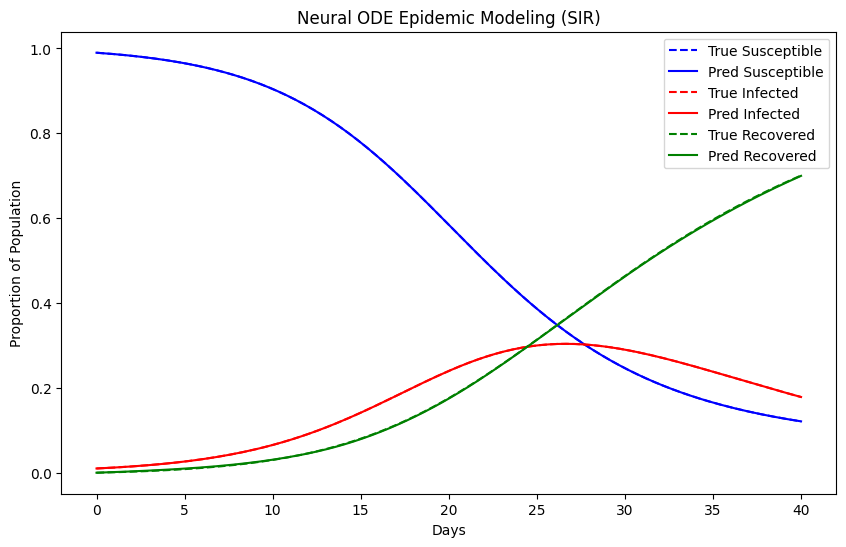

In [ ]:
# Plot Results
#
with torch.no_grad():
    # Evaluate across the entire timeline starting back at absolute t=0
    final_predictions = odeint(func, initial_state, t_data)
plt.figure(figsize=(10, 6))
labels = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']
for i in range(3):
    plt.plot(t_data.numpy(), true_y[:, i].numpy(), label=f'True {labels[i]}', color=colors[i], linestyle='--')
    plt.plot(t_data.numpy(), final_predictions[:, i].numpy(), label=f'Pred {labels[i]}', color=colors[i])

plt.title('Neural ODE Epidemic Modeling (SIR)')
plt.xlabel('Days')
plt.ylabel('Proportion of Population')
plt.legend()
plt.show()

# Comparing PINN with NODE - under unknow (stationary) beta and partially known physics
Note: UDE for SciML have varying forms. One of it is using NODE with some physics

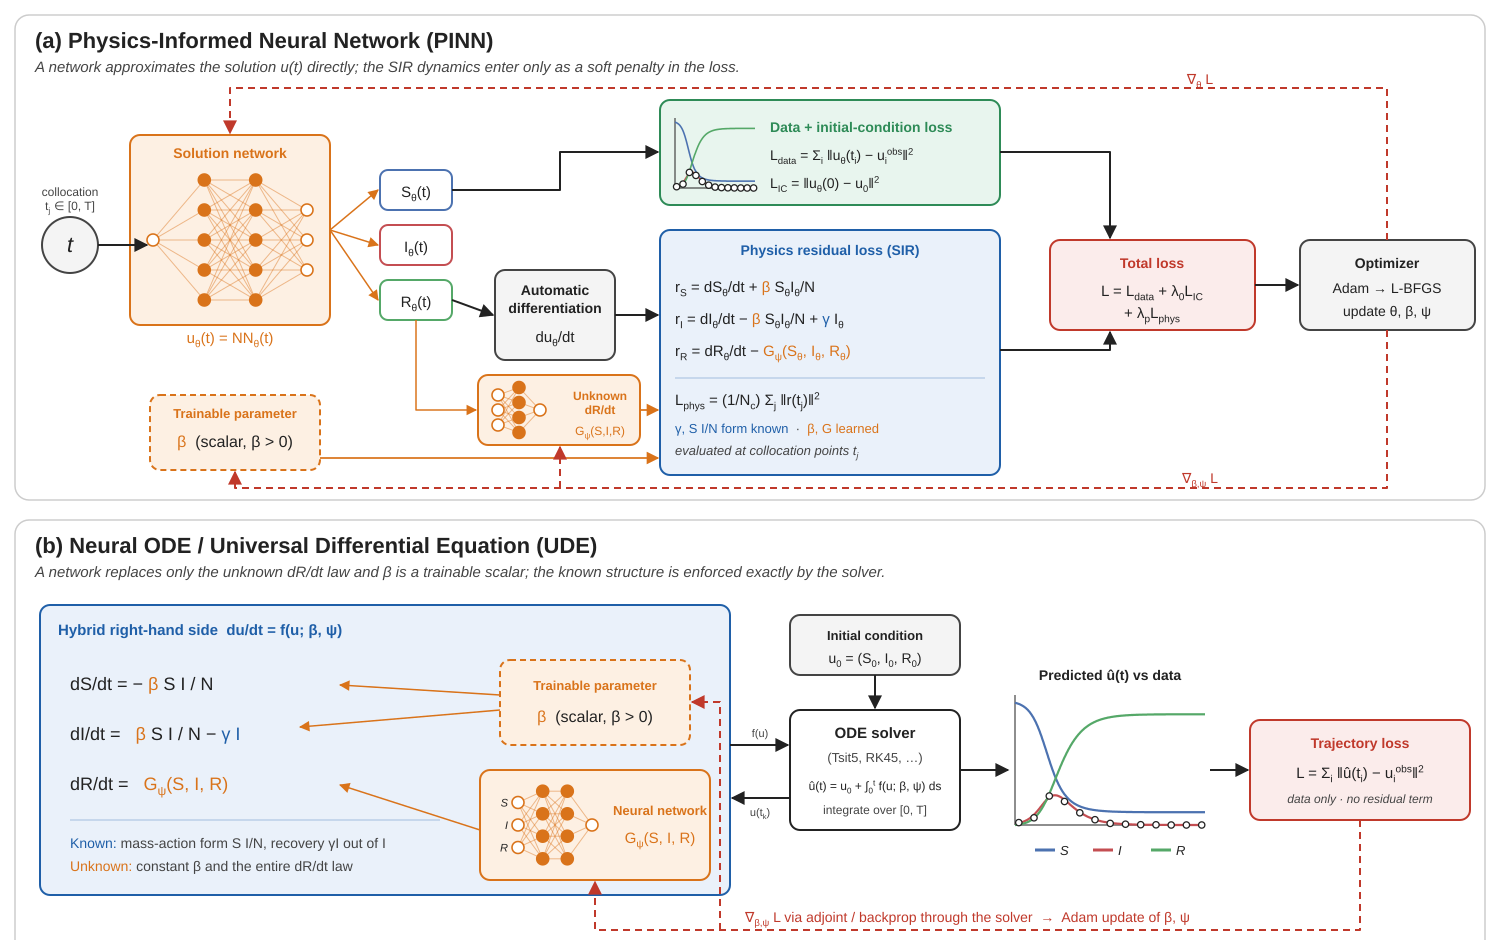

In [ ]:
# @title
# PINN vs Neural ODE/UDE figure: SIR with constant trainable beta and unknown dR/dt
# Saves pinn_vs_neuralode_sir_const_beta.svg and displays it below the cell.
import re, html
import numpy as np
from IPython.display import SVG, display

W, H = 1500, 940
FONT = "Liberation Sans, DejaVu Sans, Arial, sans-serif"
BLUE, BLUE_BG = "#1f5fa8", "#eaf1fa"
ORANGE, ORANGE_BG = "#d9731a", "#fdf0e3"
RED = "#c0392b"
GREEN, GREEN_BG = "#2e8b57", "#e8f5ee"
GRAY, GRAY_BG = "#444", "#f4f4f4"
INK = "#222"

out = []
def add(s): out.append(s)

def rich(s, size):
    """Mini markup: _{sub}, ^{sup}, [o]orange[/], [b]blue[/], [r]red[/]."""
    toks = re.split(r'(_\{[^}]*\}|\^\{[^}]*\}|\[[obrg]\]|\[/\])', s)
    colors = {'o': ORANGE, 'b': BLUE, 'r': RED, 'g': GREEN}
    res, pend, col = [], 0.0, None
    for t in toks:
        if not t: continue
        if re.fullmatch(r'\[[obrg]\]', t): col = colors[t[1]]; continue
        if t == '[/]': col = None; continue
        fill = f' fill="{col}"' if col else ''
        if t.startswith('_{') or t.startswith('^{'):
            d = 0.28*size if t[0] == '_' else -0.38*size
            res.append(f'<tspan dy="{pend+d:.1f}" font-size="{0.68*size:.1f}"{fill}>{html.escape(t[2:-1])}</tspan>')
            pend = -d
        else:
            res.append(f'<tspan dy="{pend:.1f}"{fill}>{html.escape(t)}</tspan>')
            pend = 0.0
    return ''.join(res)

def text(x, y, s, size=15, anchor="start", weight="normal", color=INK, style="normal"):
    add(f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" font-weight="{weight}" '
        f'font-style="{style}" fill="{color}">{rich(s, size)}</text>')

def box(x, y, w, h, stroke, fill, r=10, sw=2, dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"{d}/>')

def arrow(pts, color=INK, sw=2, dash=None, head=True):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    p = " ".join(f"{x},{y}" for x, y in pts)
    m = f' marker-end="url(#ah-{color[1:]})"' if head else ''
    add(f'<polyline points="{p}" fill="none" stroke="{color}" stroke-width="{sw}" stroke-linejoin="round"{d}{m}/>')

def nn(x, y, w, h, layers=(2, 4, 4, 3)):
    """Draw a feed-forward NN glyph inside rectangle."""
    xs = np.linspace(x+18, x+w-18, len(layers))
    pos = []
    for lx, n in zip(xs, layers):
        ys = np.linspace(y+h/2-(n-1)*h/(2*max(layers)), y+h/2+(n-1)*h/(2*max(layers)), n) if n > 1 else [y+h/2]
        pos.append([(lx, ly) for ly in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                add(f'<line x1="{p[0]:.1f}" y1="{p[1]:.1f}" x2="{q[0]:.1f}" y2="{q[1]:.1f}" stroke="{ORANGE}" stroke-opacity="0.45" stroke-width="1"/>')
    for li, layer in enumerate(pos):
        for p in layer:
            f = "#fff" if li in (0, len(pos)-1) else ORANGE
            add(f'<circle cx="{p[0]:.1f}" cy="{p[1]:.1f}" r="6" fill="{f}" stroke="{ORANGE}" stroke-width="1.6"/>')
    return pos

# ---------- SIR curves for mini-plots ----------
def sir(T=160, n=400, beta=0.25, gamma=0.1):
    dt = T/n; S, I, R = 0.99, 0.01, 0.0; tr = []
    for _ in range(n):
        tr.append((S, I, R))
        dS = -beta*S*I; dI = beta*S*I-gamma*I; dR = gamma*I
        S += dt*dS; I += dt*dI; R += dt*dR
    return np.array(tr)
TR = sir()
def mini_plot(x, y, w, h, dots=True, lw=2.2):
    add(f'<line x1="{x}" y1="{y+h}" x2="{x+w}" y2="{y+h}" stroke="{GRAY}" stroke-width="1.2"/>')
    add(f'<line x1="{x}" y1="{y}" x2="{x}" y2="{y+h}" stroke="{GRAY}" stroke-width="1.2"/>')
    t = np.linspace(x, x+w, len(TR))
    for k, c in zip(range(3), ["#4c72b0", "#c44e52", "#55a868"]):
        pts = " ".join(f"{a:.1f},{y+h-b*h*0.95:.1f}" for a, b in zip(t, TR[:, k]))
        add(f'<polyline points="{pts}" fill="none" stroke="{c}" stroke-width="{lw}"/>')
    if dots:
        rng = np.random.default_rng(3)
        for i in range(8, len(TR), 32):
            v = TR[i, 1]*(1+rng.normal(0, 0.12))
            add(f'<circle cx="{t[i]:.1f}" cy="{y+h-v*h*0.95:.1f}" r="3.2" fill="#fff" stroke="{INK}" stroke-width="1.3"/>')

# ---------- header ----------
add(f'<svg xmlns="http://www.w3.org/2000/svg" xml:space="preserve" width="{W}" height="{H}" viewBox="0 0 {W} {H}" font-family="{FONT}">')
add('<defs>')
for c in [INK, RED, BLUE, ORANGE, GREEN, GRAY]:
    add(f'<marker id="ah-{c[1:]}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
        f'<path d="M0,0 L10,5 L0,10 z" fill="{c}"/></marker>')
add('</defs>')
add(f'<rect width="{W}" height="{H}" fill="#fff"/>')

# =================== PANEL (a) PINN ===================
add(f'<rect x="15" y="15" width="{W-30}" height="485" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, 48, "(a) Physics-Informed Neural Network (PINN)", 22, weight="bold")
text(35, 72, "A network approximates the solution u(t) directly; the SIR dynamics enter only as a soft penalty in the loss.", 15, color=GRAY, style="italic")

add(f'<circle cx="70" cy="245" r="28" fill="{GRAY_BG}" stroke="{GRAY}" stroke-width="2"/>')
text(70, 252, "t", 22, anchor="middle", style="italic")
text(70, 196, "collocation", 12, anchor="middle", color=GRAY)
text(70, 210, "t_{j} ∈ [0, T]", 12, anchor="middle", color=GRAY)

box(130, 135, 200, 190, ORANGE, ORANGE_BG)
text(230, 158, "Solution network", 14, anchor="middle", weight="bold", color=ORANGE)
nn(135, 165, 190, 150, layers=(1, 5, 5, 3))
text(230, 343, "[o]u_{θ}(t) = NN_{θ}(t)[/]", 15, anchor="middle")
arrow([(98, 245), (147, 245)])

box(150, 395, 170, 75, ORANGE, ORANGE_BG, dash="6,4")
text(235, 418, "Trainable parameter", 13, anchor="middle", weight="bold", color=ORANGE)
text(235, 447, "[o]β[/]  (scalar, β > 0)", 16, anchor="middle")

for i, (lab, c) in enumerate([("S", "#4c72b0"), ("I", "#c44e52"), ("R", "#55a868")]):
    yy = 170 + i*55
    box(380, yy, 72, 40, c, "#fff", r=8)
    text(416, yy+27, f"{lab}_{{θ}}(t)", 15, anchor="middle")
    arrow([(330, 230), (378, yy+20)], color=ORANGE, sw=1.5)

box(660, 100, 340, 105, GREEN, GREEN_BG)
mini_plot(675, 118, 80, 70, dots=True, lw=1.6)
text(770, 132, "Data + initial-condition loss", 14, weight="bold", color=GREEN)
text(770, 160, "L_{data} = Σ_{i} ‖u_{θ}(t_{i}) − u_{i}^{obs}‖^{2}", 14)
text(770, 188, "L_{IC} = ‖u_{θ}(0) − u_{0}‖^{2}", 14)
arrow([(452, 190), (560, 190), (560, 152), (658, 152)], color=INK)

box(495, 270, 120, 90, GRAY, GRAY_BG)
text(555, 295, "Automatic", 14, anchor="middle", weight="bold")
text(555, 313, "differentiation", 14, anchor="middle", weight="bold")
text(555, 342, "du_{θ}/dt", 15, anchor="middle")
arrow([(452, 300), (493, 315)])

box(660, 230, 340, 245, BLUE, BLUE_BG)
text(830, 255, "Physics residual loss (SIR)", 14, anchor="middle", weight="bold", color=BLUE)
text(675, 292, "r_{S} = dS_{θ}/dt + [o]β[/] S_{θ}I_{θ}/N", 15)
text(675, 324, "r_{I} = dI_{θ}/dt − [o]β[/] S_{θ}I_{θ}/N + [b]γ[/] I_{θ}", 15)
text(675, 356, "r_{R} = dR_{θ}/dt − [o]G_{ψ}(S_{θ}, I_{θ}, R_{θ})[/]", 15)
add(f'<line x1="675" y1="378" x2="985" y2="378" stroke="{BLUE}" stroke-opacity="0.35"/>')
text(675, 405, "L_{phys} = (1/N_{c}) Σ_{j} ‖r(t_{j})‖^{2}", 15)
text(675, 433, "[b]γ, S I/N form known[/]  ·  [o]β, G learned[/]", 13, color=GRAY)
text(675, 455, "evaluated at collocation points t_{j}", 13, color=GRAY, style="italic")
arrow([(615, 315), (658, 315)])
arrow([(320, 458), (658, 458)], color=ORANGE, sw=1.8)

box(478, 375, 162, 70, ORANGE, ORANGE_BG)
nn(480, 380, 78, 60, layers=(3, 4, 1))
text(600, 400, "Unknown", 12, anchor="middle", weight="bold", color=ORANGE)
text(600, 414, "dR/dt", 12, anchor="middle", weight="bold", color=ORANGE)
text(600, 435, "[o]G_{ψ}(S,I,R)[/]", 12, anchor="middle")
arrow([(416, 320), (416, 410), (476, 410)], color=ORANGE, sw=1.5)
arrow([(640, 410), (658, 410)], color=ORANGE, sw=1.8)

box(1050, 240, 205, 90, RED, "#fbeceb")
text(1152, 268, "Total loss", 14, anchor="middle", weight="bold", color=RED)
text(1152, 296, "L = L_{data} + λ_{0}L_{IC}", 15, anchor="middle")
text(1152, 318, "+ λ_{p}L_{phys}", 15, anchor="middle")
arrow([(1000, 152), (1110, 152), (1110, 238)])
arrow([(1000, 350), (1110, 350), (1110, 332)])

box(1300, 240, 175, 90, GRAY, GRAY_BG)
text(1387, 268, "Optimizer", 14, anchor="middle", weight="bold")
text(1387, 293, "Adam → L-BFGS", 14, anchor="middle")
text(1387, 316, "update θ, β, ψ", 14, anchor="middle")
arrow([(1255, 285), (1298, 285)])

arrow([(1387, 240), (1387, 88), (230, 88), (230, 133)], color=RED, dash="7,5")
arrow([(1387, 330), (1387, 488), (235, 488), (235, 472)], color=RED, dash="7,5")
arrow([(560, 488), (560, 447)], color=RED, dash="7,5")
text(1200, 84, "∇_{θ} L", 14, anchor="middle", color=RED)
text(1200, 483, "∇_{β,ψ} L", 14, anchor="middle", color=RED)

# =================== PANEL (b) Neural ODE / UDE ===================
oy = 520
add(f'<rect x="15" y="{oy}" width="{W-30}" height="440" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, oy+33, "(b) Neural ODE / Universal Differential Equation (UDE)", 22, weight="bold")
text(35, oy+57, "A network replaces only the unknown dR/dt law and β is a trainable scalar; the known structure is enforced exactly by the solver.", 15, color=GRAY, style="italic")

rx, ry, rw, rh = 40, oy+85, 690, 290
box(rx, ry, rw, rh, BLUE, BLUE_BG)
text(rx+18, ry+30, "Hybrid right-hand side  du/dt = f(u; β, ψ)", 15, weight="bold", color=BLUE)
text(rx+30, ry+85, "dS/dt = − [o]β[/] S I / N", 18)
text(rx+30, ry+135, "dI/dt =   [o]β[/] S I / N − [b]γ I[/]", 18)
text(rx+30, ry+185, "dR/dt =   [o]G_{ψ}(S, I, R)[/]", 18)
add(f'<line x1="{rx+30}" y1="{ry+215}" x2="{rx+400}" y2="{ry+215}" stroke="{BLUE}" stroke-opacity="0.35"/>')
text(rx+30, ry+243, "[b]Known:[/] mass-action form S I/N, recovery γI out of I", 14, color=GRAY)
text(rx+30, ry+266, "[o]Unknown:[/] constant β and the entire dR/dt law", 14, color=GRAY)

nx, nw = rx+440, 230
by, bh = ry+45, 105
box(nx+20, by+10, nw-40, 85, ORANGE, ORANGE_BG, dash="6,4")
text(nx+nw/2, by+40, "Trainable parameter", 13, anchor="middle", weight="bold", color=ORANGE)
text(nx+nw/2, by+72, "[o]β[/]  (scalar, β > 0)", 16, anchor="middle")
gy0, gh = ry+165, 110
box(nx, gy0, nw, gh, ORANGE, ORANGE_BG)
p2 = nn(nx+20, gy0+10, 110, gh-20, layers=(3, 4, 4, 1))
for (px_, py_), lab in zip(p2[0], "SIR"):
    text(px_-10, py_+4, lab, 11, anchor="end", style="italic")
text(nx+180, gy0+45, "Neural network", 13, anchor="middle", weight="bold", color=ORANGE)
text(nx+180, gy0+73, "[o]G_{ψ}(S, I, R)[/]", 15, anchor="middle")
arrow([(nx+20, by+45), (rx+300, ry+80)], color=ORANGE, sw=1.5)
arrow([(nx+20, by+60), (rx+260, ry+122)], color=ORANGE, sw=1.5)
arrow([(nx, gy0+60), (rx+300, ry+180)], color=ORANGE, sw=1.5)

box(790, oy+95, 170, 60, GRAY, GRAY_BG)
text(875, oy+120, "Initial condition", 13, anchor="middle", weight="bold")
text(875, oy+143, "u_{0} = (S_{0}, I_{0}, R_{0})", 14, anchor="middle")
sx, sy = 790, oy+190
box(sx, sy, 170, 120, INK, "#fff")
text(sx+85, sy+28, "ODE solver", 15, anchor="middle", weight="bold")
text(sx+85, sy+52, "(Tsit5, RK45, …)", 13, anchor="middle", color=GRAY)
text(sx+85, sy+80, "û(t) = u_{0} + ∫_{0}^{t} f(u; β, ψ) ds", 12, anchor="middle")
text(sx+85, sy+104, "integrate over [0, T]", 12, anchor="middle", color=GRAY)
arrow([(875, oy+155), (875, sy-2)])
arrow([(730, sy+35), (788, sy+35)])
arrow([(790, sy+88), (732, sy+88)])
text(760, sy+27, "f(u)", 11, anchor="middle", color=GRAY)
text(760, sy+106, "u(t_{k})", 11, anchor="middle", color=GRAY)

px, py = 1015, oy+175
text(px+95, py-15, "Predicted û(t) vs data", 14, anchor="middle", weight="bold")
mini_plot(px, py, 190, 130, dots=True)
for i, (lab, c) in enumerate([("S", "#4c72b0"), ("I", "#c44e52"), ("R", "#55a868")]):
    add(f'<line x1="{px+20+i*58}" y1="{py+155}" x2="{px+40+i*58}" y2="{py+155}" stroke="{c}" stroke-width="3"/>')
    text(px+45+i*58, py+160, lab, 13, style="italic")
arrow([(960, sy+60), (1008, sy+60)])

lx, ly = 1250, oy+200
box(lx, ly, 220, 100, RED, "#fbeceb")
text(lx+110, ly+28, "Trajectory loss", 14, anchor="middle", weight="bold", color=RED)
text(lx+110, ly+58, "L = Σ_{i} ‖û(t_{i}) − u_{i}^{obs}‖^{2}", 15, anchor="middle")
text(lx+110, ly+83, "data only · no residual term", 12, anchor="middle", color=GRAY, style="italic")
arrow([(1210, ly+50), (lx-2, ly+50)])

gy = oy+410
arrow([(lx+110, ly+100), (lx+110, gy), (nx+nw/2, gy), (nx+nw/2, gy0+gh+2)], color=RED, dash="7,5")
arrow([(nx+nw+10, gy), (nx+nw+10, by+52), (nx+nw-18, by+52)], color=RED, dash="7,5")
text(745, gy-8, "∇_{β,ψ} L via adjoint / backprop through the solver  →  Adam update of β, ψ", 14, color=RED)

# =================== legend ===================
ly0 = 985
items = [(BLUE, BLUE_BG, "Known mechanistic physics"), (ORANGE, ORANGE_BG, "Learned network / parameter"),
         (GREEN, GREEN_BG, "Observed data"), (RED, "#fbeceb", "Loss")]
x = 40
for st, fi, lab in items:
    box(x, ly0, 26, 18, st, fi, r=4)
    text(x+34, ly0+14, lab, 14)
    x += 34 + len(lab)*7.6 + 40
arrow([(x, ly0+9), (x+40, ly0+9)], color=RED, dash="7,5")
text(x+50, ly0+14, "Gradient flow", 14)
x += 180
arrow([(x, ly0+9), (x+40, ly0+9)])
text(x+50, ly0+14, "Forward pass", 14)

add('</svg>')

# ---------- save + show ----------
svg_str = "\n".join(out)
with open("pinn_vs_neuralode_sir_const_beta.svg", "w", encoding="utf-8") as f:
    f.write(svg_str)
display(SVG(svg_str))

# Overview of PINN and NODE when unknown beta is non-stationary, and partially known physics

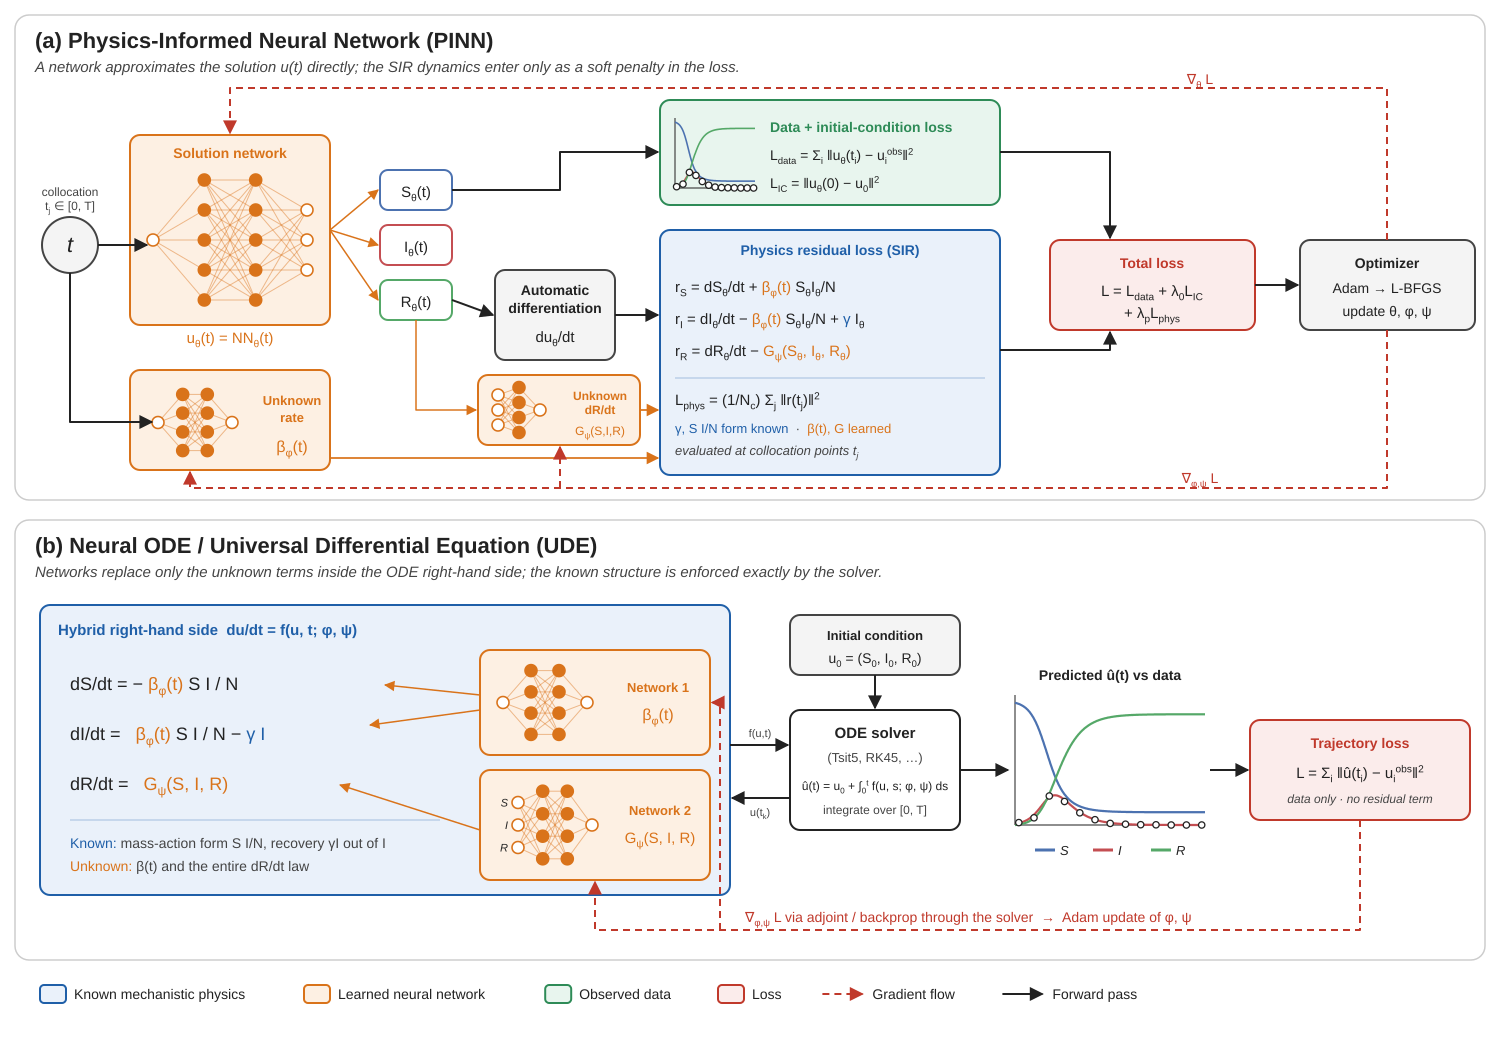

ok


In [ ]:
# @title

import re, html
import numpy as np

W, H = 1500, 1040
FONT = "Liberation Sans, DejaVu Sans, Arial, sans-serif"
BLUE, BLUE_BG = "#1f5fa8", "#eaf1fa"
ORANGE, ORANGE_BG = "#d9731a", "#fdf0e3"
RED = "#c0392b"
GREEN, GREEN_BG = "#2e8b57", "#e8f5ee"
GRAY, GRAY_BG = "#444", "#f4f4f4"
INK = "#222"

out = []
def add(s): out.append(s)

def rich(s, size):
    """Mini markup: _{sub}, ^{sup}, [o]orange[/], [b]blue[/], [r]red[/]."""
    toks = re.split(r'(_\{[^}]*\}|\^\{[^}]*\}|\[[obrg]\]|\[/\])', s)
    colors = {'o': ORANGE, 'b': BLUE, 'r': RED, 'g': GREEN}
    res, pend, col = [], 0.0, None
    for t in toks:
        if not t: continue
        if re.fullmatch(r'\[[obrg]\]', t): col = colors[t[1]]; continue
        if t == '[/]': col = None; continue
        fill = f' fill="{col}"' if col else ''
        if t.startswith('_{') or t.startswith('^{'):
            d = 0.28*size if t[0] == '_' else -0.38*size
            res.append(f'<tspan dy="{pend+d:.1f}" font-size="{0.68*size:.1f}"{fill}>{html.escape(t[2:-1])}</tspan>')
            pend = -d
        else:
            res.append(f'<tspan dy="{pend:.1f}"{fill}>{html.escape(t)}</tspan>')
            pend = 0.0
    return ''.join(res)

def text(x, y, s, size=15, anchor="start", weight="normal", color=INK, style="normal"):
    add(f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" font-weight="{weight}" '
        f'font-style="{style}" fill="{color}">{rich(s, size)}</text>')

def box(x, y, w, h, stroke, fill, r=10, sw=2, dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    add(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" fill="{fill}" stroke="{stroke}" stroke-width="{sw}"{d}/>')

def arrow(pts, color=INK, sw=2, dash=None, head=True):
    d = f' stroke-dasharray="{dash}"' if dash else ''
    p = " ".join(f"{x},{y}" for x, y in pts)
    m = f' marker-end="url(#ah-{color[1:]})"' if head else ''
    add(f'<polyline points="{p}" fill="none" stroke="{color}" stroke-width="{sw}" stroke-linejoin="round"{d}{m}/>')

def nn(x, y, w, h, layers=(2, 4, 4, 3), nin=None, nout=None):
    """Draw a feed-forward NN glyph inside rectangle."""
    xs = np.linspace(x+18, x+w-18, len(layers))
    pos = []
    for lx, n in zip(xs, layers):
        ys = np.linspace(y+h/2-(n-1)*h/(2*max(layers)), y+h/2+(n-1)*h/(2*max(layers)), n) if n > 1 else [y+h/2]
        pos.append([(lx, ly) for ly in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                add(f'<line x1="{p[0]:.1f}" y1="{p[1]:.1f}" x2="{q[0]:.1f}" y2="{q[1]:.1f}" stroke="{ORANGE}" stroke-opacity="0.45" stroke-width="1"/>')
    for li, layer in enumerate(pos):
        for p in layer:
            f = "#fff" if li in (0, len(pos)-1) else ORANGE
            add(f'<circle cx="{p[0]:.1f}" cy="{p[1]:.1f}" r="6" fill="{f}" stroke="{ORANGE}" stroke-width="1.6"/>')
    return pos

# ---------- SIR curves for mini-plots ----------
def sir(T=160, n=400, beta=0.25, gamma=0.1):
    dt = T/n; S, I, R = 0.99, 0.01, 0.0; tr = []
    for _ in range(n):
        tr.append((S, I, R))
        dS = -beta*S*I; dI = beta*S*I-gamma*I; dR = gamma*I
        S += dt*dS; I += dt*dI; R += dt*dR
    return np.array(tr)
TR = sir()
def mini_plot(x, y, w, h, dots=True, lw=2.2):
    add(f'<line x1="{x}" y1="{y+h}" x2="{x+w}" y2="{y+h}" stroke="{GRAY}" stroke-width="1.2"/>')
    add(f'<line x1="{x}" y1="{y}" x2="{x}" y2="{y+h}" stroke="{GRAY}" stroke-width="1.2"/>')
    t = np.linspace(x, x+w, len(TR))
    for k, c in zip(range(3), ["#4c72b0", "#c44e52", "#55a868"]):
        pts = " ".join(f"{a:.1f},{y+h-b*h*0.95:.1f}" for a, b in zip(t, TR[:, k]))
        add(f'<polyline points="{pts}" fill="none" stroke="{c}" stroke-width="{lw}"/>')
    if dots:
        rng = np.random.default_rng(3)
        for i in range(8, len(TR), 32):
            v = TR[i, 1]*(1+rng.normal(0, 0.12))
            add(f'<circle cx="{t[i]:.1f}" cy="{y+h-v*h*0.95:.1f}" r="3.2" fill="#fff" stroke="{INK}" stroke-width="1.3"/>')

# ---------- header ----------
add(f'<svg xmlns="http://www.w3.org/2000/svg" xml:space="preserve" width="{W}" height="{H}" viewBox="0 0 {W} {H}" font-family="{FONT}">')
add('<defs>')
for c in [INK, RED, BLUE, ORANGE, GREEN, GRAY]:
    add(f'<marker id="ah-{c[1:]}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
        f'<path d="M0,0 L10,5 L0,10 z" fill="{c}"/></marker>')
add('</defs>')
add(f'<rect width="{W}" height="{H}" fill="#fff"/>')

# =================== PANEL (a) PINN ===================
add(f'<rect x="15" y="15" width="{W-30}" height="485" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, 48, "(a) Physics-Informed Neural Network (PINN)", 22, weight="bold")
text(35, 72, "A network approximates the solution u(t) directly; the SIR dynamics enter only as a soft penalty in the loss.", 15, color=GRAY, style="italic")

# input t
add(f'<circle cx="70" cy="245" r="28" fill="{GRAY_BG}" stroke="{GRAY}" stroke-width="2"/>')
text(70, 252, "t", 22, anchor="middle", style="italic")
text(70, 196, "collocation", 12, anchor="middle", color=GRAY)
text(70, 210, "t_{j} ∈ [0, T]", 12, anchor="middle", color=GRAY)

# solution NN
box(130, 135, 200, 190, ORANGE, ORANGE_BG)
text(230, 158, "Solution network", 14, anchor="middle", weight="bold", color=ORANGE)
nn(135, 165, 190, 150, layers=(1, 5, 5, 3))
text(230, 343, "[o]u_{θ}(t) = NN_{θ}(t)[/]", 15, anchor="middle")
arrow([(98, 245), (147, 245)])

# unknown-function NN
box(130, 370, 200, 100, ORANGE, ORANGE_BG, dash="0")
nn(140, 385, 110, 75, layers=(1, 4, 4, 1))
text(292, 405, "Unknown", 13, anchor="middle", weight="bold", color=ORANGE)
text(292, 422, "rate", 13, anchor="middle", weight="bold", color=ORANGE)
text(292, 452, "[o]β_{φ}(t)[/]", 16, anchor="middle")
arrow([(70, 273), (70, 422), (152, 422)])  # t -> beta net (passes below labels)

# outputs
for i, (lab, c) in enumerate([("S", "#4c72b0"), ("I", "#c44e52"), ("R", "#55a868")]):
    yy = 170 + i*55
    box(380, yy, 72, 40, c, "#fff", r=8)
    text(416, yy+27, f"{lab}_{{θ}}(t)", 15, anchor="middle")
    arrow([(330, 230), (378, yy+20)], color=ORANGE, sw=1.5)

# data loss box (top)
box(660, 100, 340, 105, GREEN, GREEN_BG)
mini_plot(675, 118, 80, 70, dots=True, lw=1.6)
text(770, 132, "Data + initial-condition loss", 14, weight="bold", color=GREEN)
text(770, 160, "L_{data} = Σ_{i} ‖u_{θ}(t_{i}) − u_{i}^{obs}‖^{2}", 14)
text(770, 188, "L_{IC} = ‖u_{θ}(0) − u_{0}‖^{2}", 14)
arrow([(452, 190), (560, 190), (560, 152), (658, 152)], color=INK)

# AD box
box(495, 270, 120, 90, GRAY, GRAY_BG)
text(555, 295, "Automatic", 14, anchor="middle", weight="bold")
text(555, 313, "differentiation", 14, anchor="middle", weight="bold")
text(555, 342, "du_{θ}/dt", 15, anchor="middle")
arrow([(452, 300), (493, 315)])

# residual box
box(660, 230, 340, 245, BLUE, BLUE_BG)
text(830, 255, "Physics residual loss (SIR)", 14, anchor="middle", weight="bold", color=BLUE)
text(675, 292, "r_{S} = dS_{θ}/dt + [o]β_{φ}(t)[/] S_{θ}I_{θ}/N", 15)
text(675, 324, "r_{I} = dI_{θ}/dt − [o]β_{φ}(t)[/] S_{θ}I_{θ}/N + [b]γ[/] I_{θ}", 15)
text(675, 356, "r_{R} = dR_{θ}/dt − [o]G_{ψ}(S_{θ}, I_{θ}, R_{θ})[/]", 15)
add(f'<line x1="675" y1="378" x2="985" y2="378" stroke="{BLUE}" stroke-opacity="0.35"/>')
text(675, 405, "L_{phys} = (1/N_{c}) Σ_{j} ‖r(t_{j})‖^{2}", 15)
text(675, 433, "[b]γ, S I/N form known[/]  ·  [o]β(t), G learned[/]", 13, color=GRAY)
text(675, 455, "evaluated at collocation points t_{j}", 13, color=GRAY, style="italic")
arrow([(615, 315), (658, 315)])
arrow([(330, 458), (658, 458)], color=ORANGE, sw=1.8)
# unknown dR/dt network
box(478, 375, 162, 70, ORANGE, ORANGE_BG)
nn(480, 380, 78, 60, layers=(3, 4, 1))
text(600, 400, "Unknown", 12, anchor="middle", weight="bold", color=ORANGE)
text(600, 414, "dR/dt", 12, anchor="middle", weight="bold", color=ORANGE)
text(600, 435, "[o]G_{ψ}(S,I,R)[/]", 12, anchor="middle")
arrow([(416, 320), (416, 410), (476, 410)], color=ORANGE, sw=1.5)
arrow([(640, 410), (658, 410)], color=ORANGE, sw=1.8)

# total loss
box(1050, 240, 205, 90, RED, "#fbeceb")
text(1152, 268, "Total loss", 14, anchor="middle", weight="bold", color=RED)
text(1152, 296, "L = L_{data} + λ_{0}L_{IC}", 15, anchor="middle")
text(1152, 318, "+ λ_{p}L_{phys}", 15, anchor="middle")
arrow([(1000, 152), (1110, 152), (1110, 238)])
arrow([(1000, 350), (1110, 350), (1110, 332)])

# optimizer
box(1300, 240, 175, 90, GRAY, GRAY_BG)
text(1387, 268, "Optimizer", 14, anchor="middle", weight="bold")
text(1387, 293, "Adam → L-BFGS", 14, anchor="middle")
text(1387, 316, "update θ, φ, ψ", 14, anchor="middle")
arrow([(1255, 285), (1298, 285)])

# gradient flows (dashed red)
arrow([(1387, 240), (1387, 88), (230, 88), (230, 133)], color=RED, dash="7,5")
arrow([(1387, 330), (1387, 488), (190, 488), (190, 472)], color=RED, dash="7,5")
arrow([(560, 488), (560, 447)], color=RED, dash="7,5")
text(1200, 84, "∇_{θ} L", 14, anchor="middle", color=RED)
text(1200, 483, "∇_{φ,ψ} L", 14, anchor="middle", color=RED)

# =================== PANEL (b) Neural ODE / UDE ===================
oy = 520
add(f'<rect x="15" y="{oy}" width="{W-30}" height="440" rx="14" fill="none" stroke="#ccc" stroke-width="1.5"/>')
text(35, oy+33, "(b) Neural ODE / Universal Differential Equation (UDE)", 22, weight="bold")
text(35, oy+57, "Networks replace only the unknown terms inside the ODE right-hand side; the known structure is enforced exactly by the solver.", 15, color=GRAY, style="italic")

# hybrid RHS
rx, ry, rw, rh = 40, oy+85, 690, 290
box(rx, ry, rw, rh, BLUE, BLUE_BG)
text(rx+18, ry+30, "Hybrid right-hand side  du/dt = f(u, t; φ, ψ)", 15, weight="bold", color=BLUE)
text(rx+30, ry+85, "dS/dt = − [o]β_{φ}(t)[/] S I / N", 18)
text(rx+30, ry+135, "dI/dt =   [o]β_{φ}(t)[/] S I / N − [b]γ I[/]", 18)
text(rx+30, ry+185, "dR/dt =   [o]G_{ψ}(S, I, R)[/]", 18)
add(f'<line x1="{rx+30}" y1="{ry+215}" x2="{rx+400}" y2="{ry+215}" stroke="{BLUE}" stroke-opacity="0.35"/>')
text(rx+30, ry+243, "[b]Known:[/] mass-action form S I/N, recovery γI out of I", 14, color=GRAY)
text(rx+30, ry+266, "[o]Unknown:[/] β(t) and the entire dR/dt law", 14, color=GRAY)

# NNs inside RHS
nx, nw = rx+440, 230
by, bh = ry+45, 105
box(nx, by, nw, bh, ORANGE, ORANGE_BG)
nn(nx+5, by+10, 120, bh-20, layers=(1, 4, 4, 1))
text(nx+178, by+42, "Network 1", 13, anchor="middle", weight="bold", color=ORANGE)
text(nx+178, by+70, "[o]β_{φ}(t)[/]", 16, anchor="middle")
gy0, gh = ry+165, 110
box(nx, gy0, nw, gh, ORANGE, ORANGE_BG)
p2 = nn(nx+20, gy0+10, 110, gh-20, layers=(3, 4, 4, 1))
for (px_, py_), lab in zip(p2[0], "SIR"):
    text(px_-10, py_+4, lab, 11, anchor="end", style="italic")
text(nx+180, gy0+45, "Network 2", 13, anchor="middle", weight="bold", color=ORANGE)
text(nx+180, gy0+73, "[o]G_{ψ}(S, I, R)[/]", 15, anchor="middle")
arrow([(nx, by+45), (rx+345, ry+80)], color=ORANGE, sw=1.5)
arrow([(nx, by+60), (rx+330, ry+120)], color=ORANGE, sw=1.5)
arrow([(nx, gy0+60), (rx+300, ry+180)], color=ORANGE, sw=1.5)
# IC + solver
box(790, oy+95, 170, 60, GRAY, GRAY_BG)
text(875, oy+120, "Initial condition", 13, anchor="middle", weight="bold")
text(875, oy+143, "u_{0} = (S_{0}, I_{0}, R_{0})", 14, anchor="middle")
sx, sy = 790, oy+190
box(sx, sy, 170, 120, INK, "#fff")
text(sx+85, sy+28, "ODE solver", 15, anchor="middle", weight="bold")
text(sx+85, sy+52, "(Tsit5, RK45, …)", 13, anchor="middle", color=GRAY)
text(sx+85, sy+80, "û(t) = u_{0} + ∫_{0}^{t} f(u, s; φ, ψ) ds", 12, anchor="middle")
text(sx+85, sy+104, "integrate over [0, T]", 12, anchor="middle", color=GRAY)
arrow([(875, oy+155), (875, sy-2)])
# loop between RHS and solver
arrow([(730, sy+35), (788, sy+35)])
arrow([(790, sy+88), (732, sy+88)])
text(760, sy+27, "f(u,t)", 11, anchor="middle", color=GRAY)
text(760, sy+106, "u(t_{k})", 11, anchor="middle", color=GRAY)

# trajectories
px, py = 1015, oy+175
text(px+95, py-15, "Predicted û(t) vs data", 14, anchor="middle", weight="bold")
mini_plot(px, py, 190, 130, dots=True)
for i, (lab, c) in enumerate([("S", "#4c72b0"), ("I", "#c44e52"), ("R", "#55a868")]):
    add(f'<line x1="{px+20+i*58}" y1="{py+155}" x2="{px+40+i*58}" y2="{py+155}" stroke="{c}" stroke-width="3"/>')
    text(px+45+i*58, py+160, lab, 13, style="italic")
arrow([(960, sy+60), (1008, sy+60)])

# loss
lx, ly = 1250, oy+200
box(lx, ly, 220, 100, RED, "#fbeceb")
text(lx+110, ly+28, "Trajectory loss", 14, anchor="middle", weight="bold", color=RED)
text(lx+110, ly+58, "L = Σ_{i} ‖û(t_{i}) − u_{i}^{obs}‖^{2}", 15, anchor="middle")
text(lx+110, ly+83, "data only · no residual term", 12, anchor="middle", color=GRAY, style="italic")
arrow([(1210, ly+50), (lx-2, ly+50)])

# gradient (adjoint)
gy = oy+410
arrow([(lx+110, ly+100), (lx+110, gy), (nx+nw/2, gy), (nx+nw/2, gy0+gh+2)], color=RED, dash="7,5")
arrow([(nx+nw+10, gy), (nx+nw+10, by+bh/2), (nx+nw+2, by+bh/2)], color=RED, dash="7,5")
text(745, gy-8, "∇_{φ,ψ} L via adjoint / backprop through the solver  →  Adam update of φ, ψ", 14, color=RED)

# =================== legend ===================
ly0 = 985
items = [(BLUE, BLUE_BG, "Known mechanistic physics", None), (ORANGE, ORANGE_BG, "Learned neural network", None),
         (GREEN, GREEN_BG, "Observed data", None), (RED, "#fbeceb", "Loss", None)]
x = 40
for st, fi, lab, _ in items:
    box(x, ly0, 26, 18, st, fi, r=4)
    text(x+34, ly0+14, lab, 14)
    x += 34 + len(lab)*7.6 + 40
arrow([(x, ly0+9), (x+40, ly0+9)], color=RED, dash="7,5")
text(x+50, ly0+14, "Gradient flow", 14)
x += 180
arrow([(x, ly0+9), (x+40, ly0+9)])
text(x+50, ly0+14, "Forward pass", 14)
from IPython.display import SVG, display
display(SVG(filename="pinn_vs_neuralode_sir.svg"))

add('</svg>')
open("pinn_vs_neuralode_sir.svg", "w").write("\n".join(out))
print("ok")
